In [1]:
from pathlib import Path
from IPython.display import display, Image
print('SEM PSD analysis: counted particles only; Miles–Lantuejoul weights; 20,000 independent particle and field bootstrap replicates.')
print('All bootstrap intervals are conditional on detection and, for Al, a fixed size scale. See report.md for assumptions and limitations.')

SEM PSD analysis: counted particles only; Miles–Lantuejoul weights; 20,000 independent particle and field bootstrap replicates.
All bootstrap intervals are conditional on detection and, for Al, a fixed size scale. See report.md for assumptions and limitations.


In [2]:
#!/usr/bin/env python3
"""Weighted SEM PSD, bootstrap intervals, tail scenarios and Al scaling.
Run: python analysis.py --input-dir /workspace --output-dir /workspace/outputs --bootstrap 20000
Dependencies: numpy, pandas, scipy, matplotlib. All intervals are percentile 95%.
"""
from pathlib import Path
import argparse, json, hashlib
import numpy as np
import pandas as pd
from scipy import stats, optimize, special
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt


def fit_model(x, weights, model, lower=15.):
    lx=np.log(x); weights=weights/weights.sum()
    if model=='lognormal':
        def obj(p):
            mu, ls=p; sig=np.exp(ls)
            ll=-lx-ls-.5*((lx-mu)/sig)**2-.5*np.log(2*np.pi)-stats.norm.logsf((np.log(lower)-mu)/sig)
            return -weights@ll
        mu=weights@lx
        start=[mu,np.log(np.sqrt(weights@(lx-mu)**2))]
        bounds=[(0,8),(-4,2)]
    else:
        def obj(p):
            k, scale=np.exp(p)
            z=k*(lx-np.log(scale))
            ll=np.log(k)-np.log(scale)+(k-1)*(lx-np.log(scale))-np.exp(np.clip(z,-700,700))+(lower/scale)**k
            return -weights@ll
        start=np.log([2.,weights@x]); bounds=[(-3,3),(0,8)]
    res=optimize.minimize(obj,start,method='L-BFGS-B',bounds=bounds,
                          options={'ftol':1e-13,'gtol':1e-7,'maxiter':1000})
    assert res.success, res.message
    p=(res.x[0],np.exp(res.x[1])) if model=='lognormal' else tuple(np.exp(res.x))
    dist=stats.lognorm(s=p[1],scale=np.exp(p[0])) if model=='lognormal' else stats.weibull_min(c=p[0],scale=p[1])
    return p,dist,float(res.fun)


def third_partial(model,p,t):
    """Integral_0^t d^3 f_number(d) dd."""
    if model=='lognormal':
        mu,s=p
        return np.exp(3*mu+4.5*s*s)*stats.norm.cdf((np.log(t)-mu-3*s*s)/s)
    k,scale=p
    return scale**3*special.gamma(1+3/k)*special.gammainc(1+3/k,(t/scale)**k)


def main(input_dir,output_dir,B=20000,seed=20261027):
    root=Path(input_dir); out=Path(output_dir); out.mkdir(parents=True,exist_ok=True)
    raw=pd.read_csv(root/'nab_k7m2q9_particles.csv')
    fields=pd.read_csv(root/'fields.csv')
    assert raw.included.dtype==bool
    s=raw.loc[raw.included].sort_values('ecd_um').reset_index(drop=True)
    d=s.ecd_um.to_numpy(); w=s.weight.to_numpy(); v=w*d**3; n=len(d)
    assert np.isfinite(d).all() and np.isfinite(w).all() and (w>0).all() and (d>0).all()
    ratio=((.85/2400)/(1.25/7000))**(1/3)
    ratios={'NAB':1.,'Al_estimate':ratio,
            'Al_property_low':((.8/2400)/(1.3/7000))**(1/3),
            'Al_property_high':((.9/2400)/(1.2/7000))**(1/3)}
    cuts=[10,15,20,25,32,45,63,250]
    # All cuts share identical bootstrap draws, preserving correlations in window/ratio statistics.
    basegrid=np.unique(np.r_[np.arange(0,401,.5),*[np.array(cuts)/r for r in ratios.values()]])
    pos=np.searchsorted(d,basegrid,side='left') # all threshold statistics are strictly <t
    def cumvalues(cw):
        c=np.r_[0.,np.cumsum(cw)]
        return c[pos]/c[-1]
    point=np.stack([cumvalues(w),cumvalues(v)])
    rng=np.random.default_rng(seed)
    # Multinomial multiplicities are exactly an ordinary n-out-of-n particle bootstrap.
    pb=np.empty((B,2,len(basegrid)),dtype=np.float64)
    for a in range(0,B,100):
        b=min(B,a+100)
        counts=rng.multinomial(n,np.full(n,1/n),size=b-a)
        for j,ww in enumerate([w,v]):
            cs=np.cumsum(counts*ww,axis=1)
            vals=np.zeros((b-a,len(basegrid)))
            valid=pos>0
            vals[:,valid]=cs[:,pos[valid]-1]
            pb[a:b,j]=vals/cs[:,-1,None]
    names=np.sort(s.field.unique()); nf=len(names)
    # Draw 9 complete field clusters with replacement, keeping all particle weights unchanged.
    fc=rng.multinomial(nf,np.full(nf,1/nf),size=B)
    fb=np.empty_like(pb)
    for j,ww in enumerate([w,v]):
        nums=[]; dens=[]
        for f in names:
            z=ww*(s.field.to_numpy()==f)
            nums.append(np.r_[0.,np.cumsum(z)][pos]); dens.append(z.sum())
        fb[:,j]=([email redacted](nums))/([email redacted](dens))[:,None]
    bands={'particle':np.quantile(pb,[.025,.975],axis=0),
           'field':np.quantile(fb,[.025,.975],axis=0)}
    def at(arr,power,t,r=1.):
        target=t/r
        ix=int(np.argmin(np.abs(basegrid-target)))
        assert abs(basegrid[ix]-target)<1e-8
        return arr[...,power,ix]
    rows=[]
    def add(material,label,weighting,fn,unit='percent'):
        j=0 if weighting=='number' else 1
        record={'material':material,'metric':label,'weighting':weighting,'unit':unit,
                'estimate':100*float(fn(point,j))}
        for typ,boot in [('particle',pb),('field',fb)]:
            lo,hi=100*np.quantile(fn(boot,j),[.025,.975])
            record.update({typ+'_lo':lo,typ+'_hi':hi})
        rows.append(record)
    for material,r in ratios.items():
        for t in cuts:
            for wt in ['number','volume']:
                add(material,f'below_{t}',wt,lambda a,j,t=t,r=r:at(a,j,t,r))
        for lower,upper in [(20,63),(15,45),(20,45),(0,63)]:
            for wt in ['number','volume']:
                add(material,f'window_{lower}_{upper}',wt,
                    lambda a,j,l=lower,u=upper,r=r:at(a,j,u,r)-(at(a,j,l,r) if l else 0))
        for upper in [63,45]:
            for lower in [20,15]:
                for wt in ['number','volume']:
                    add(material,f'below_{lower}_given_below_{upper}',wt,
                        lambda a,j,l=lower,u=upper,r=r:at(a,j,l,r)/at(a,j,u,r),
                        'g_per_100g' if wt=='volume' else 'percent')
    metrics=pd.DataFrame(rows); metrics.to_csv(out/'fractions_and_intervals.csv',index=False)
    # Export the exact empirical step distributions and pointwise bands on a separate common grid.
    curve=pd.DataFrame({'ecd_um_NAB':d,'ecd_um_Al_estimate':d*ratio,
                        'Q0_percent':100*np.cumsum(w)/w.sum(),
                        'Q3_percent':100*np.cumsum(v)/v.sum()})
    curve.to_csv(out/'empirical_distributions.csv',index=False)
    bandframe=pd.DataFrame({'NAB_threshold_um':basegrid,'Al_threshold_um':basegrid*ratio})
    for j,qn in enumerate(['Q0','Q3']):
        bandframe[qn+'_percent']=point[j]*100
        for typ,bnd in bands.items():
            for k,label in enumerate(['lo','hi']): bandframe[f'{qn}_{typ}_{label}']=bnd[k,j]*100
    bandframe.to_csv(out/'cdf_pointwise_intervals.csv',index=False)
    qrows=[]
    for j,ww in enumerate([w,v]):
        c=np.cumsum(ww)/ww.sum()
        qrows.append({'weighting':['number','volume'][j],**{f'D{int(q*100)}_um':d[np.searchsorted(c,q)] for q in [.1,.5,.9]}})
    pd.DataFrame(qrows).to_csv(out/'quantiles.csv',index=False)
    # Per-field diagnostics; field areas are NOT used to renormalize the pooled population.
    fr=[]
    for _,field in fields.iterrows():
        sf=s.loc[s.field==field.field]; a=sf.ecd_um.to_numpy(); b=sf.weight.to_numpy()
        fr.append({'field':field.field,'n':len(sf),'own_area_mm2':field.own_area_um2/1e6,
                   'nominal_cutoff_um':10*field.px_um,'weight_sum':b.sum(),
                   'volume_proxy_sum':(b*a**3).sum(),
                   'below20_number_percent':100*b[a<20].sum()/b.sum(),
                   'below20_volume_percent':100*(b*a**3)[a<20].sum()/(b*a**3).sum(),
                   'below63_volume_percent':100*(b*a**3)[a<63].sum()/(b*a**3).sum()})
    pd.DataFrame(fr).to_csv(out/'field_diagnostics.csv',index=False)
    # Truncated fits use number weights. The Weibull (Rosin-Rammler) here is a NUMBER model,
    # not a mass-distribution fit; volume predictions are obtained from third moments.
    fit=d>=15; modelrows=[]; fit_details={}
    finegrid=np.linspace(.1,30,600)
    modelcurves=pd.DataFrame({'diameter_um':finegrid})
    for model in ['lognormal','weibull']:
        p,dist,nll=fit_model(d[fit],w[fit],model)
        S15=dist.sf(15)
        # Field-specific missing population: anchor number intensity to observed >=15 per field.
        # Approximate cutoff L=10 px_um from context. This is a scenario, not calibrated completeness.
        missnum={10:0.,15:0.}; missvol={10:0.,15:0.}
        for _,field in fields.iterrows():
            nfine=w[(s.field.to_numpy()==field.field)&fit].sum()/S15
            L=10*field.px_um
            for t in [10,15]:
                lim=min(t,L)
                missnum[t]+=nfine*dist.cdf(lim)
                missvol[t]+=nfine*third_partial(model,p,lim)
        nmissing=missnum[15]; vmissing=missvol[15]
        # Tail deficit in a directly observable interval is a predictive adequacy diagnostic.
        predicted_10_15=w[fit].sum()/S15*(dist.cdf(15)-dist.cdf(10))
        observed_10_15=w[(d>=10)&(d<15)].sum()
        fullthird=dist.moment(3)
        for t in [10,15]:
            modelrows.append({'model':model,'threshold_um':t,
                'whole_model_number_percent':100*dist.cdf(t),
                'whole_model_volume_percent':100*third_partial(model,p,t)/fullthird,
                'counted_number_percent':100*w[d<t].sum()/w.sum(),
                'counted_volume_percent':100*v[d<t].sum()/v.sum(),
                'completion_number_percent':100*(w[d<t].sum()+missnum[t])/(w.sum()+nmissing),
                'completion_volume_percent':100*(v[d<t].sum()+missvol[t])/(v.sum()+vmissing),
                'missing_number_relative_to_counted_percent':100*nmissing/w.sum(),
                'missing_volume_relative_to_counted_percent':100*vmissing/v.sum()})
        empirical=np.cumsum(w[fit])/w[fit].sum()
        conditional=(dist.cdf(d[fit])-dist.cdf(15))/S15
        ks=float(np.max(np.abs(empirical-conditional)))
        fit_details[model]={'parameters':list(p),'mean_weighted_negative_log_likelihood':nll,
                            'conditional_KS_descriptive':ks,'expected_weight_10_15':predicted_10_15,
                            'observed_weight_10_15':observed_10_15}
        modelcurves[model+'_Q0_percent']=100*dist.cdf(finegrid)
    pd.DataFrame(modelrows).to_csv(out/'detection_limit_scenarios.csv',index=False)
    modelcurves.to_csv(out/'tail_model_curves.csv',index=False)
    # Equivalent sphere volume -> mass only for a constant density within a material.
    # An unobserved monodisperse population demonstrates why there is no upper bound from images alone.
    stress=[]
    for dm in [3.,5.]:
        for fm in [.001,.01]:
            mv=fm/(1-fm)*v.sum(); nw=mv/dm**3
            stress.append({'unseen_d_um':dm,'assumed_true_mass_share_percent':fm*100,
                           'true_below10_number_percent':100*(w[d<10].sum()+nw)/(w.sum()+nw),
                           'true_below10_volume_percent':100*(v[d<10].sum()+mv)/(v.sum()+mv)})
    pd.DataFrame(stress).to_csv(out/'unseen_fines_stress_test.csv',index=False)
    # Explicitly hypothetical layer: report particle fractions, not a made-up absolute layer count.
    layer=[]
    for material,r in [('NAB',1.),('Al_estimate',ratio)]:
        for upper in [np.inf,63,45]:
            keep=d*r<upper
            ww=w[keep]; dd=d[keep]*r
            layer.append({'material':material,'upper_um':upper,
                          'mean_particle_sphere_volume_um3':np.pi/6*np.sum(ww*dd**3)/ww.sum(),
                          'below20_particles_per_1000':1000*ww[dd<20].sum()/ww.sum()})
    pd.DataFrame(layer).to_csv(out/'layer_particle_factors.csv',index=False)
    # Nature-like scientific figures: data-dominant, colourblind-safe colours, no decorative frames.
    plt.rcParams.update({'font.family':'DejaVu Sans','font.size':9,'axes.labelsize':10,
                         'axes.titlesize':11,'axes.spines.top':False,'axes.spines.right':False,
                         'xtick.direction':'out','ytick.direction':'out','pdf.fonttype':42,
                         'savefig.dpi':350})
    colors=['#0072B2','#D55E00']
    def savefig(fig,name):
        fig.savefig(out/(name+'.png'),dpi=350,bbox_inches='tight')
        fig.savefig(out/(name+'.pdf'),bbox_inches='tight'); plt.close(fig)
    fig,axes=plt.subplots(2,2,figsize=(9,6.6),sharey='row',layout='constrained')
    for col,(material,r) in enumerate([('NAB',1.),('Al-12Si estimate',ratio)]):
        for row,(j,qn) in enumerate([(0,'Q0: number'),(1,'Q3: equivalent-sphere volume')]):
            ax=axes[row,col]
            ax.fill_between(basegrid*r,bands['field'][0,j]*100,bands['field'][1,j]*100,color=colors[j],alpha=.17,label='95% field bootstrap')
            ax.fill_between(basegrid*r,bands['particle'][0,j]*100,bands['particle'][1,j]*100,color=colors[j],alpha=.32,label='95% particle bootstrap')
            ax.step(d*r,np.cumsum([w,v][j])/[w,v][j].sum()*100,where='post',color=colors[j],lw=1.5,label=qn)
            for t in [15,20,45,63]: ax.axvline(t,color='.45',lw=.65,ls='--')
            ax.set(xlim=(0,400),ylim=(0,100),xlabel='Equivalent circle diameter (µm)',ylabel='Cumulative fraction (%)')
            ax.set_title(f'{material} | {qn}')
            if row==0 and col==0: ax.legend(loc='lower right',frameon=False,fontsize=7)
            ax.text(.98,.97,'Dashed cuts: 15, 20, 45, 63 µm',transform=ax.transAxes,ha='right',va='top',fontsize=7,color='.35')
    savefig(fig,'cumulative_distributions')
    fig,axes=plt.subplots(1,2,figsize=(9,3.4),layout='constrained')
    for ax,(material,r) in zip(axes,[('NAB',1.),('Al-12Si estimate',ratio)]):
        for j,qn in enumerate(['Q0 number','Q3 volume']):
            ax.fill_between(basegrid*r,bands['field'][0,j]*100,bands['field'][1,j]*100,color=colors[j],alpha=.15)
            ax.step(d*r,np.cumsum([w,v][j])/[w,v][j].sum()*100,where='post',color=colors[j],lw=1.4,label=qn)
        for t in [15,20,45,63]: ax.axvline(t,color='.45',lw=.7,ls='--')
        ax.set(xlim=(0,70),ylim=(0,100),xlabel='Equivalent circle diameter (µm)',ylabel='Cumulative fraction (%)',title=material)
        ax.legend(loc='upper left',frameon=False,fontsize=8)
    savefig(fig,'cumulative_fine_zoom')
    histrows=[]
    fig,axes=plt.subplots(1,2,figsize=(9,3.2),sharey=True,layout='constrained')
    bins=np.arange(0,31,1.)
    for ax,(material,r) in zip(axes,[('NAB',1.),('Al-12Si estimate',ratio)]):
        hist,_=np.histogram(d*r,bins=bins,weights=w)
        hp=100*hist/w.sum()
        ax.bar(bins[:-1]+.5,hp,width=.95,color=colors[0],edgecolor='white',linewidth=.3)
        # Cutoff band maps the context's nominal field-dependent limits.
        ax.axvspan(0,6.7*r,color='.85',alpha=.7)
        ax.axvspan(6.7*r,10.13*r,color='.92',alpha=.7)
        for t in [15,20]: ax.axvline(t,color='.35',ls='--',lw=.8)
        ax.set(xlim=(0,30),xlabel='Equivalent circle diameter (µm)',title=material)
        ax.text(.03,.97,'Shading: missing / partly detected range',transform=ax.transAxes,va='top',fontsize=7)
        for l,h,hval in zip(bins[:-1],bins[1:],hp):
            histrows.append({'material':material,'bin_lower_um':l,'bin_upper_um':h,'number_percent_of_all_counted':hval})
    axes[0].set_ylabel('All counted particles (% per 1 µm bin)')
    savefig(fig,'fine_number_histogram')
    pd.DataFrame(histrows).to_csv(out/'fine_number_histogram.csv',index=False)
    fig,axes=plt.subplots(1,2,figsize=(9,3.4),layout='constrained')
    for ax,j,qn in zip(axes,[0,1],['Number','Volume']):
        ax.step(d,np.cumsum([w,v][j])/[w,v][j].sum()*100,where='post',color='k',label='Counted empirical')
        for model in ['lognormal','weibull']:
            p,dist,_=fit_model(d[fit],w[fit],model)
            pred=dist.cdf(finegrid) if j==0 else third_partial(model,p,finegrid)/dist.moment(3)
            ax.plot(finegrid,100*pred,label='Log-normal' if model=='lognormal' else 'Weibull / Rosin–Rammler')
        ax.axvline(15,color='.5',lw=.8,ls='--')
        ax.set(xlim=(0,25),ylim=(0,15 if j==0 else .08),xlabel='Equivalent circle diameter (µm)',ylabel='Cumulative fraction (%)',title=f'{qn}: extrapolation is model-dependent')
        ax.legend(frameon=False,fontsize=7,loc='upper left')
    savefig(fig,'detection_limit_models')
    metadata={'rows_total':len(raw),'rows_counted':n,'fields':nf,'bootstrap_replicates':B,'seed':seed,
              'Al_scale_central':ratio,'Al_scale_property_range':[ratios['Al_property_low'],ratios['Al_property_high']],
              'fit_details':fit_details,'files_sha256':{f.name:hashlib.sha256(f.read_bytes()).hexdigest() for f in [root/'nab_k7m2q9_particles.csv',root/'fields.csv',root/'context.md']}}
    (out/'analysis_metadata.json').write_text(json.dumps(metadata,indent=2))
    return metrics,pd.DataFrame(modelrows),metadata

if False:
    ap=argparse.ArgumentParser(); ap.add_argument('--input-dir',default='/workspace');ap.add_argument('--output-dir',default='/workspace/outputs');ap.add_argument('--bootstrap',type=int,default=20000)
    args=ap.parse_args(); main(args.input_dir,args.output_dir,args.bootstrap)


In [3]:
metrics, detection, metadata = main(Path('inputs'), Path('.'), B=20000, seed=20261027)
print(json.dumps(metadata, indent=2))

{
  "rows_total": 8828,
  "rows_counted": 5937,
  "fields": 9,
  "bootstrap_replicates": 20000,
  "seed": 20261027,
  "Al_scale_central": 1.2564115023286342,
  "Al_scale_property_range": [
    1.2152840862513392,
    1.298123525462776
  ],
  "fit_details": {
    "lognormal": {
      "parameters": [
        3.896615313832729,
        0.33093352207473964
      ],
      "mean_weighted_negative_log_likelihood": 4.20862764306477,
      "conditional_KS_descriptive": 0.11650345253393324,
      "expected_weight_10_15": 1.021321214370247,
      "observed_weight_10_15": 43.287099999999995
    },
    "weibull": {
      "parameters": [
        2.034991686070954,
        55.860730346445365
      ],
      "mean_weighted_negative_log_likelihood": 4.442817653927399,
      "conditional_KS_descriptive": 0.18629883562247254,
      "expected_weight_10_15": 246.17625824548972,
      "observed_weight_10_15": 43.287099999999995
    }
  },
  "files_sha256": {
    "nab_k7m2q9_particles.csv": "d9d0951515cbe67d8

In [4]:
print('All fraction and conditional-yield results: percent or g/100g as labelled')
display(metrics[metrics.material.isin(['NAB','Al_estimate'])])
print('Detection scenarios: not confidence bounds')
display(detection)
print('Per-field diagnostics')
display(pd.read_csv('field_diagnostics.csv'))
print('Layer factors: no geometry or packing assumed')
display(pd.read_csv('layer_particle_factors.csv'))

All fraction and conditional-yield results: percent or g/100g as labelled


,material,metric,weighting,unit,estimate,particle_lo,particle_hi,field_lo,field_hi
0,NAB,below_10,number,percent,0.910906,0.624927,1.229974,0.450444,1.460762
1,NAB,below_10,volume,percent,0.002033,0.001369,0.002813,0.000689,0.004704
2,NAB,below_15,number,percent,1.593476,1.238468,1.963436,1.048268,2.395413
3,NAB,below_15,volume,percent,0.006791,0.005079,0.008725,0.004306,0.012266
4,NAB,below_20,number,percent,2.063883,1.667512,2.475426,1.426253,2.983514
...,...,...,...,...,...,...,...,...,...
59,Al_estimate,below_15_given_below_63,volume,g_per_100g,0.020456,0.015019,0.026316,0.014392,0.030075
60,Al_estimate,below_20_given_below_45,number,percent,13.960207,11.122920,16.907145,9.229246,21.091252
61,Al_estimate,below_20_given_below_45,volume,g_per_100g,0.627655,0.474306,0.796582,0.344580,1.138354
62,Al_estimate,below_15_given_below_45,number,percent,10.251017,7.660931,12.975715,6.982483,15.203578


Detection scenarios: not confidence bounds


,model,threshold_um,whole_model_number_percent,whole_model_volume_percent,counted_number_percent,counted_volume_percent,completion_number_percent,completion_volume_percent,missing_number_relative_to_counted_percent,missing_volume_relative_to_counted_percent
0,lognormal,10,0.000073,3.131689e-07,0.910906,0.002033,0.910913,0.002033,0.000008,2.191581e-08
1,lognormal,15,0.016436,2.276971e-04,1.593476,0.006791,1.593484,0.006791,0.000008,2.191581e-08
2,weibull,10,2.972408,5.244858e-03,0.910906,0.002033,2.626009,0.003349,1.765859,1.332759e-03
3,weibull,15,6.654583,3.930285e-02,1.593476,0.006791,3.301044,0.008123,1.765859,1.332759e-03


Per-field diagnostics


,field,n,own_area_mm2,nominal_cutoff_um,weight_sum,volume_proxy_sum,below20_number_percent,below20_volume_percent,below63_volume_percent
0,3.2nA_001,806,3.212317,8.99306,857.2921,1.653297e+08,1.114393,0.016875,44.389423
1,3.2nA_002,525,2.563365,8.99306,559.9779,1.419589e+08,1.336392,0.016759,35.286952
2,3.2nA_004,311,6.459353,10.12830,349.7055,6.893535e+08,5.286877,0.008210,1.525061
3,not annotated,727,2.865848,6.74479,776.6542,1.467425e+08,1.642546,0.008254,46.105612
4,spherical,725,2.865848,6.74479,778.1466,1.418452e+08,4.437146,0.037735,46.584564
5,spherical_001,782,2.843793,6.74479,830.9710,1.367303e+08,1.188694,0.017913,54.128889
6,spherical_002,882,2.865848,6.74479,936.8113,1.270461e+08,1.849102,0.033553,62.356475
7,spherical_003,791,2.684316,6.74479,839.1057,1.244249e+08,1.652867,0.029481,59.396654
8,spherical_004,388,1.395744,6.74479,413.1111,6.634474e+07,1.696202,0.013230,53.255604


Layer factors: no geometry or packing assumed


,material,upper_um,mean_particle_sphere_volume_um3,below20_particles_per_1000
0,NAB,inf,143641.873681,20.638826
1,NAB,63.0,51715.299207,24.382496
2,NAB,45.0,30165.445537,49.325103
3,Al_estimate,inf,284889.716133,16.421080
4,Al_estimate,63.0,76746.483455,26.299503
5,Al_estimate,45.0,28661.750657,139.602067


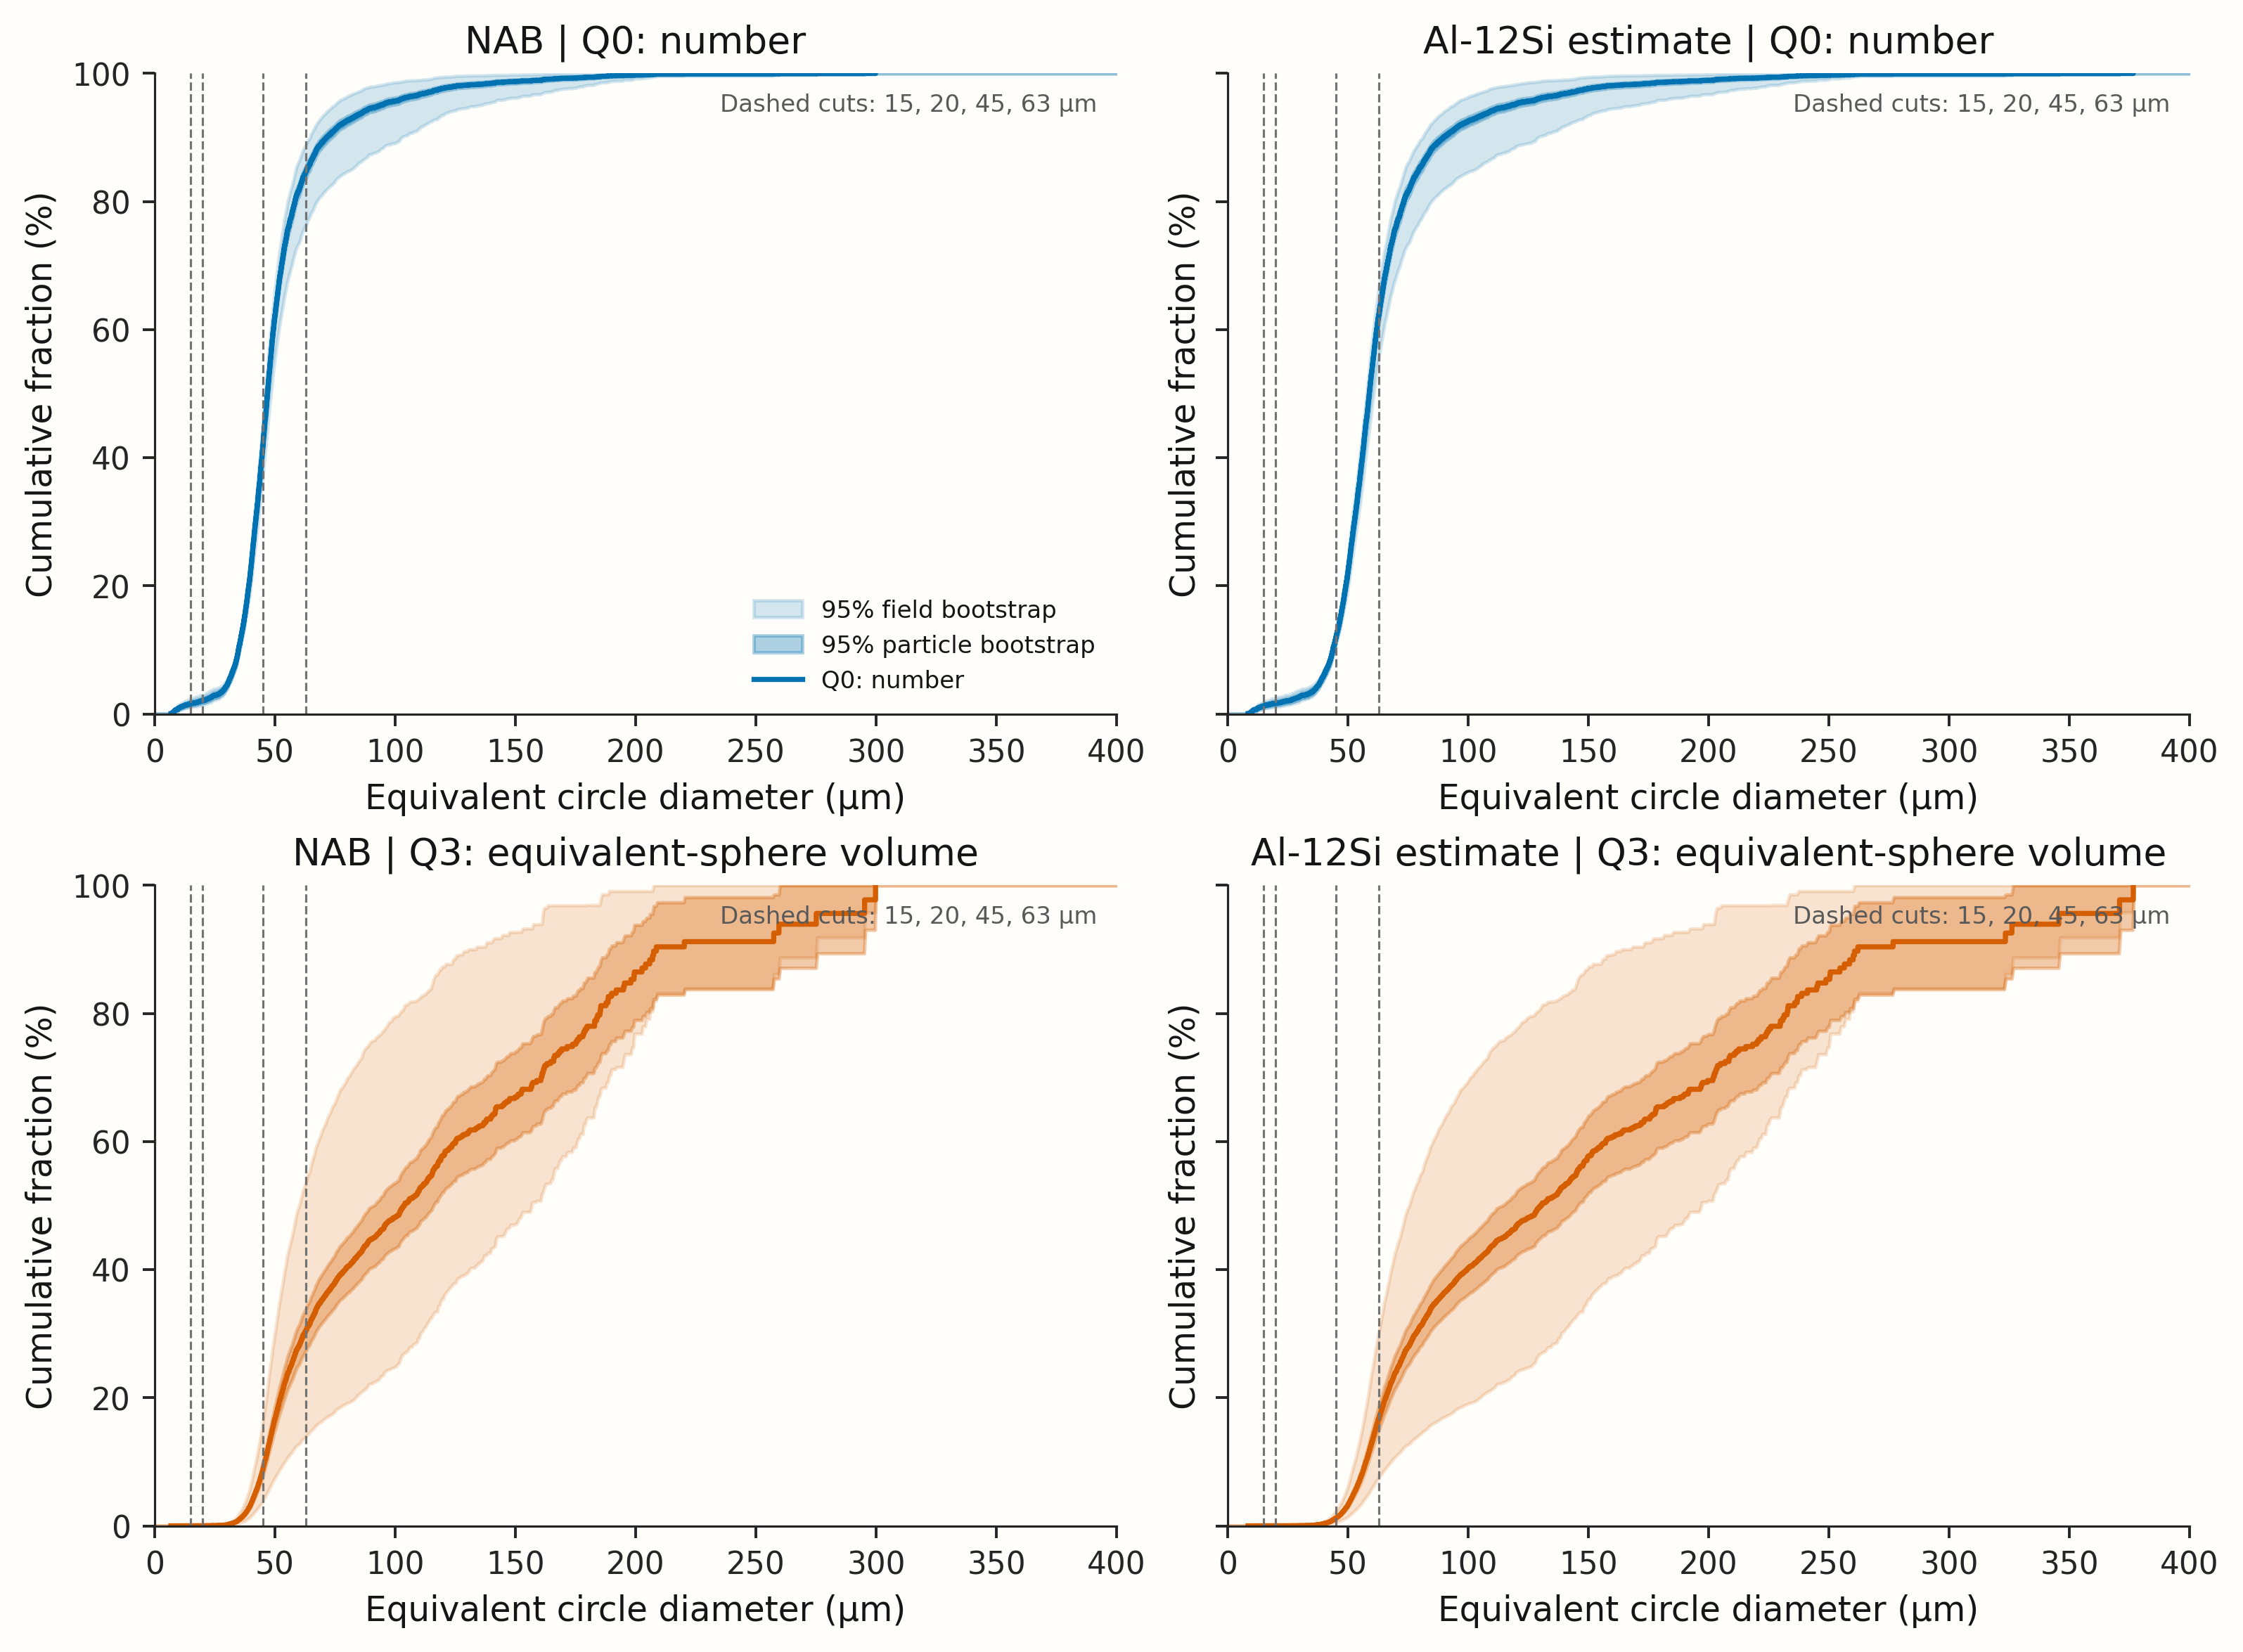

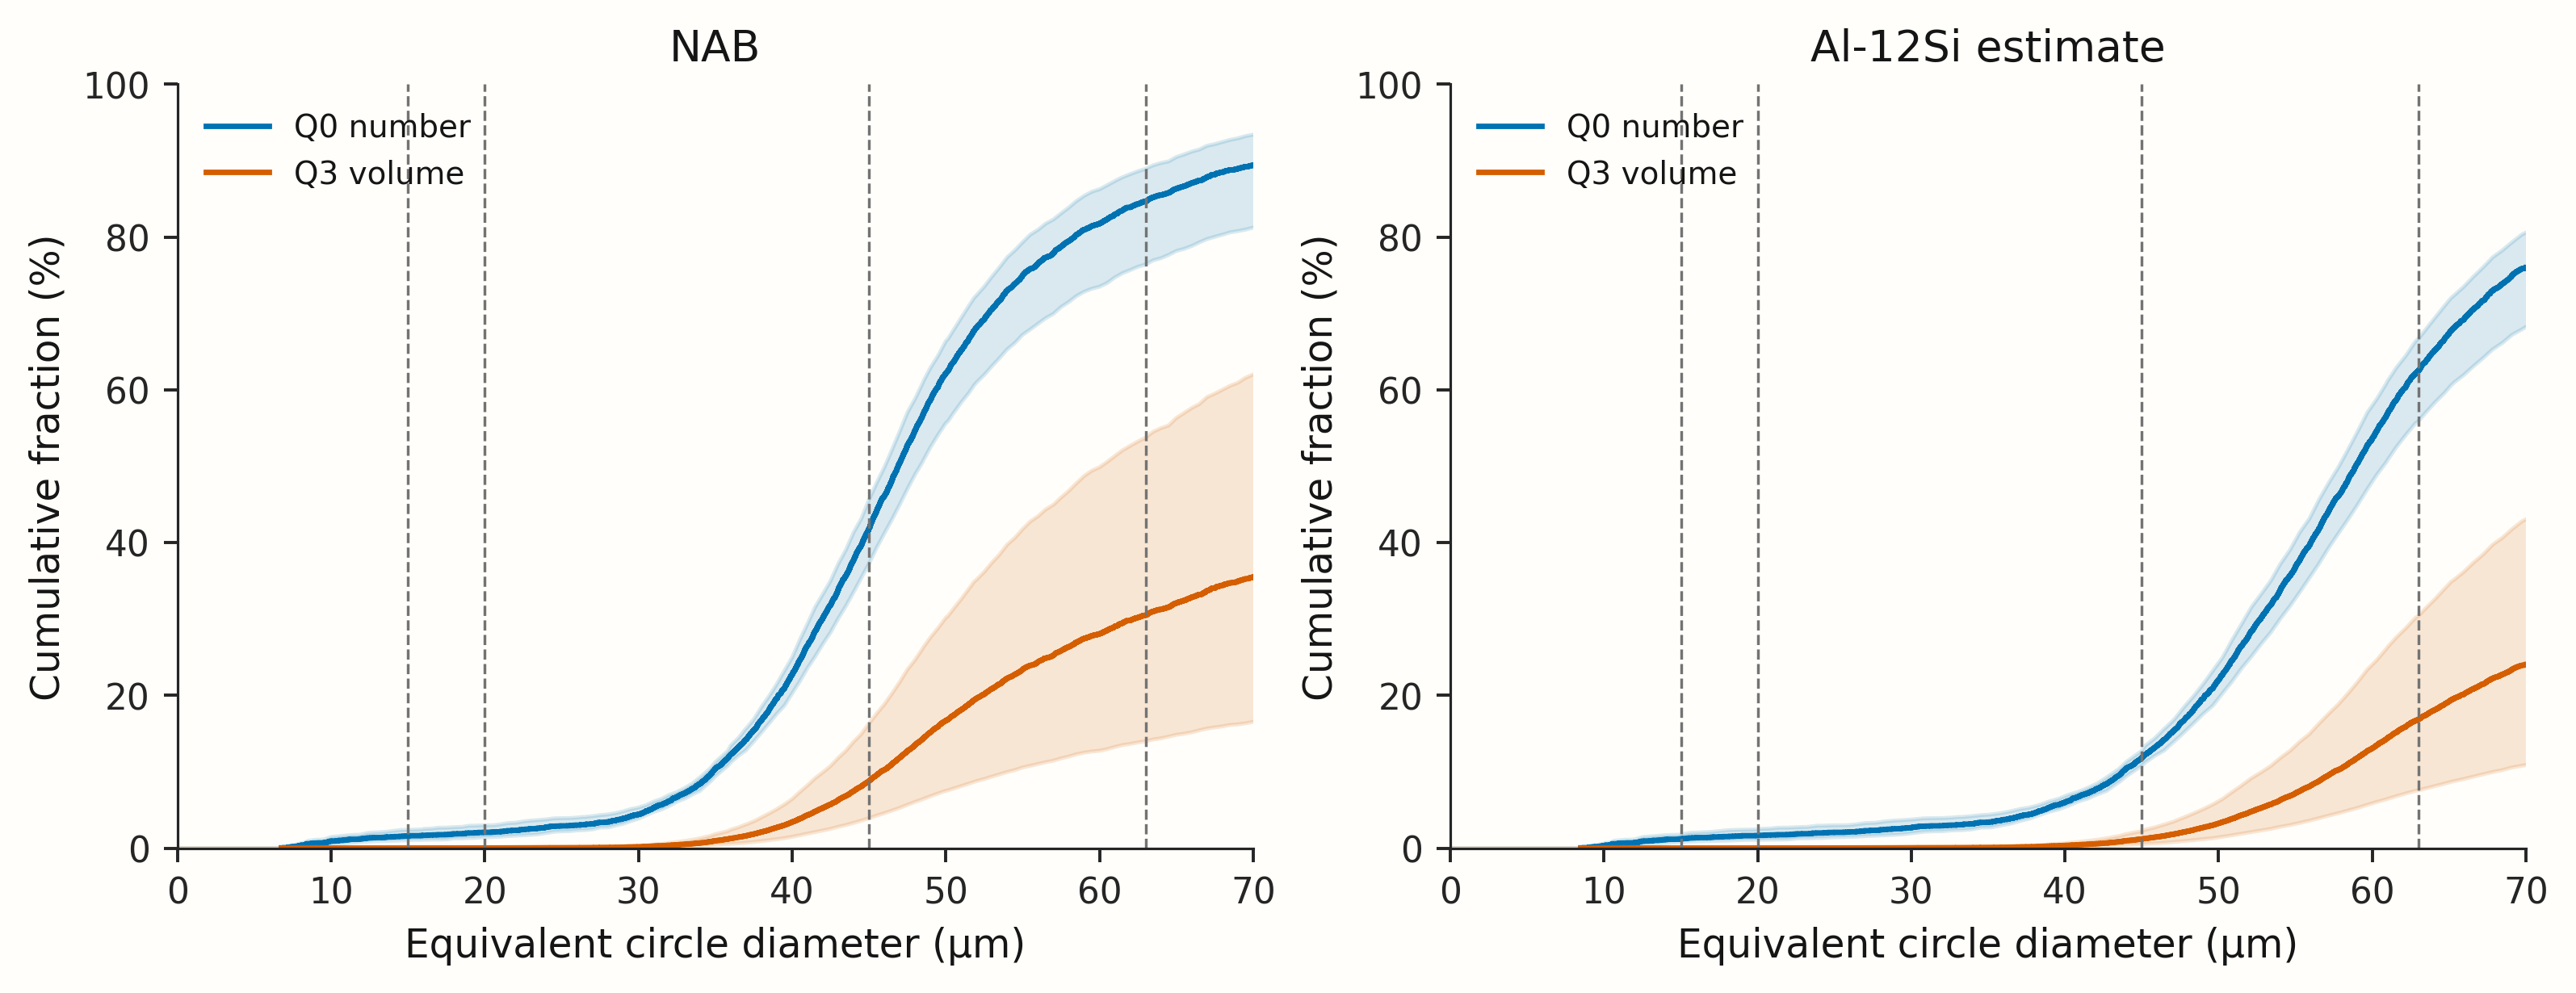

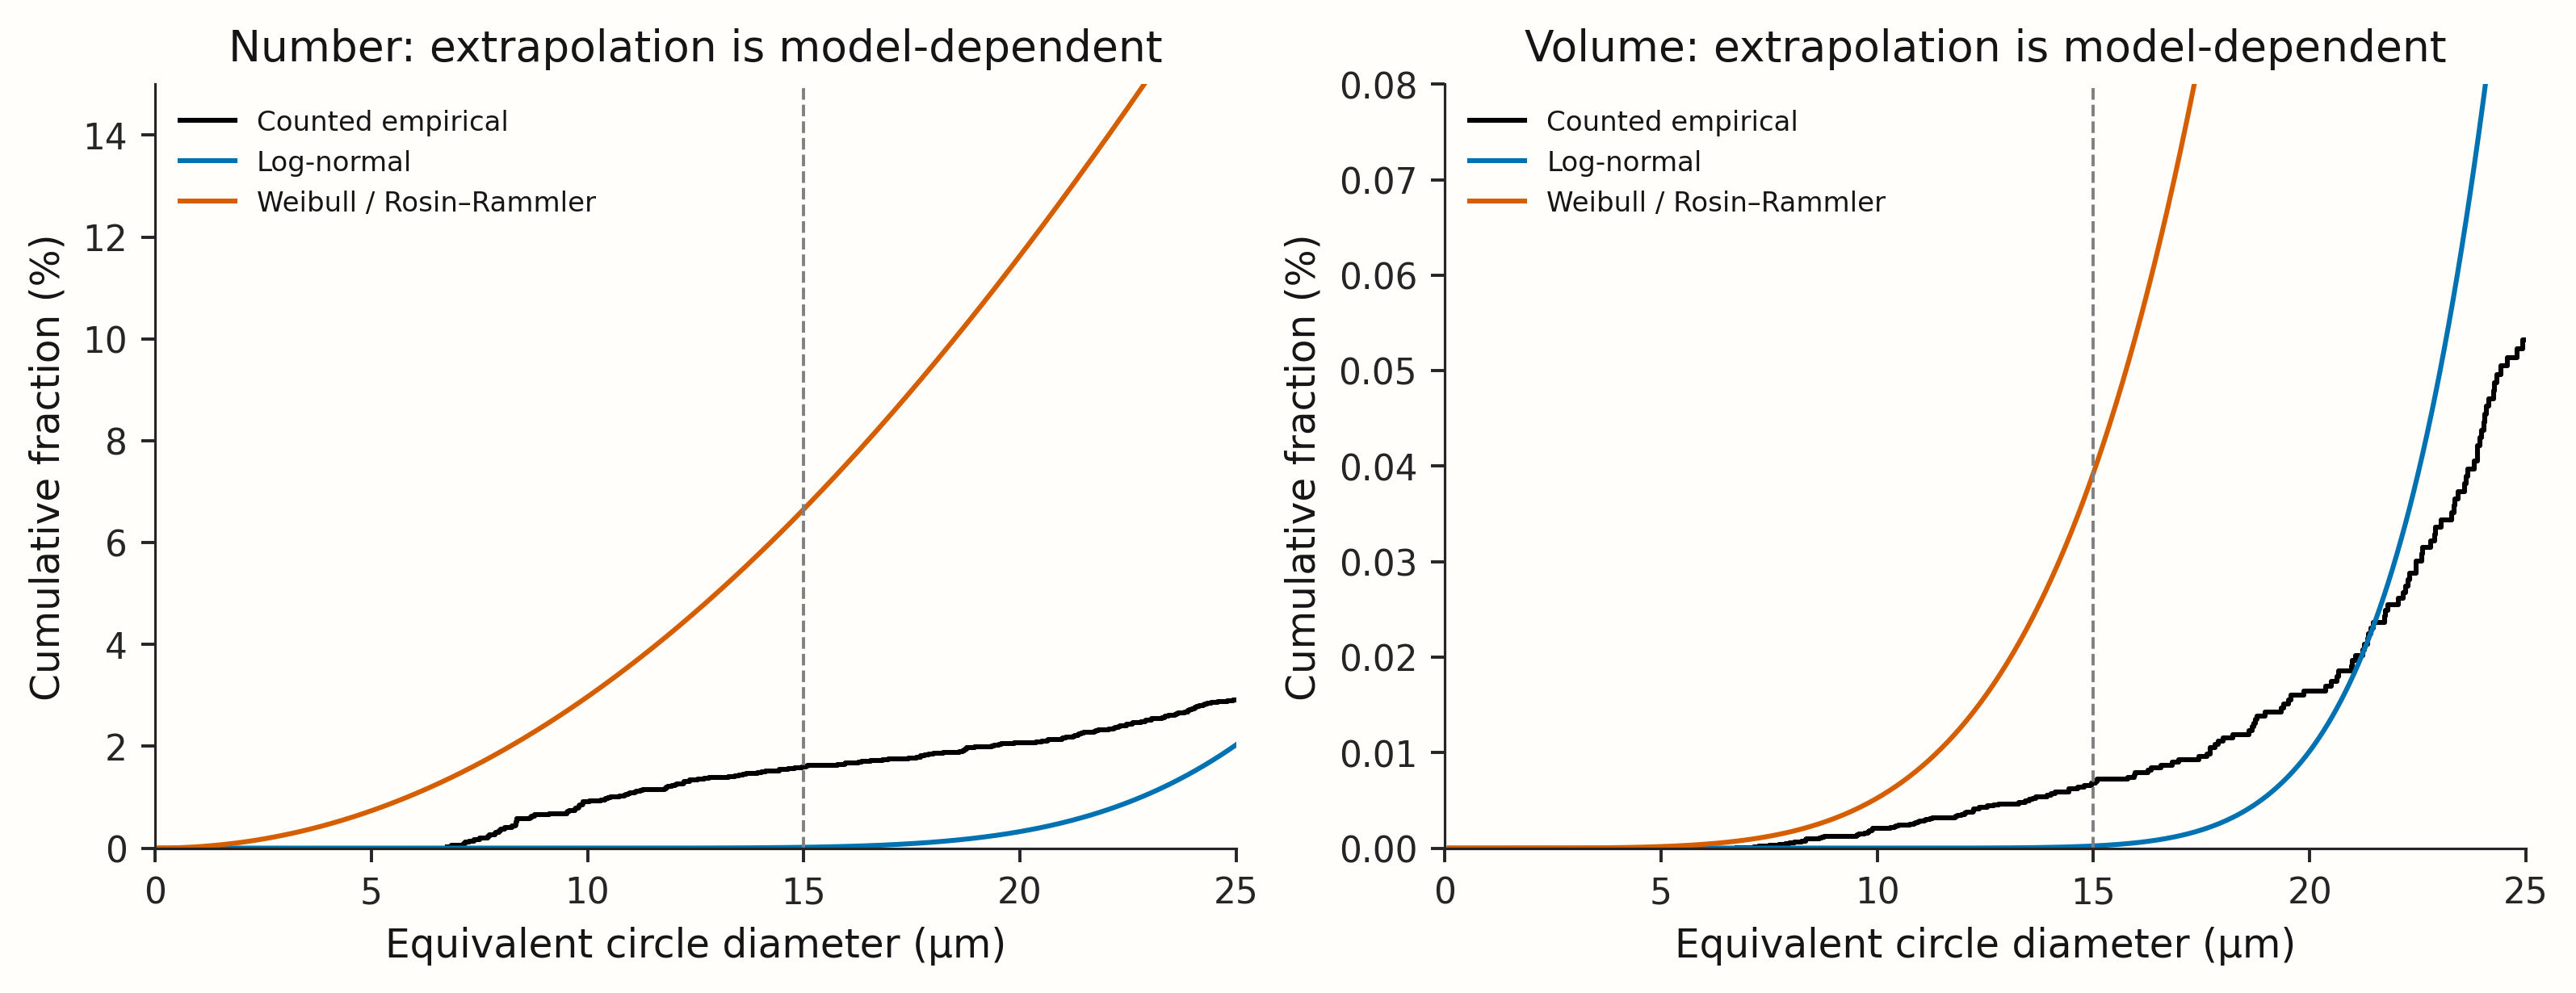

In [5]:
for name in ['cumulative_distributions','cumulative_fine_zoom','fine_number_histogram','detection_limit_models']:
    display(Image(filename=name+'.png', width=1000))

In [6]:
assert metadata['rows_counted'] == 5937
assert metadata['fields'] == 9
assert metadata['bootstrap_replicates'] == 20000
assert metrics[['estimate','particle_lo','particle_hi','field_lo','field_hi']].ge(0).all().all()
assert metrics[['estimate','particle_lo','particle_hi','field_lo','field_hi']].le(100+1e-8).all().all()
assert (metrics.particle_lo<=metrics.particle_hi).all()
assert (metrics.field_lo<=metrics.field_hi).all()
for material in metrics.material.unique():
    for wt in ['number','volume']:
        z=metrics[(metrics.material==material)&(metrics.weighting==wt)].set_index('metric')
        assert np.isclose(z.loc['window_20_63','estimate'],z.loc['below_63','estimate']-z.loc['below_20','estimate'])
        assert np.isclose(z.loc['below_20_given_below_63','estimate'],100*z.loc['below_20','estimate']/z.loc['below_63','estimate'])
print('All validation checks passed.')

All validation checks passed.
